Connected to .venv01 (3.13.11) (Python 3.13.11)

In [ ]:
# ANALYSIS DL
# SEARCH WORDS :
# YEARLY_DL_ESTIMATION
# TESTING_MAIN_WITH_CACHE
# DL_TRADER_DIAGNOSTICS
# DL_FITTED_TARGET_SPACE_PERFORMANCE
# DL_TARGET_PERFORMANCE_EXECUTED_VS_SKIPPED
# DL_SCORE_CALIBRATION_DIAGNOSTIC
# DL_SCORE_THRESHOLD_CALIBRATION
# DL_SCORE_THRESHOLD_TRADER_CALIBRATION

import pandas as pd
import numpy as np
import warnings
import os, sys
import pickle

from pathlib import Path
from arch.utility.exceptions import ConvergenceWarning

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=ConvergenceWarning)


sys.path.insert(0, "/Users/shah/CODE_BOOK_4/THESIS_WORKING/THESIS_2")
sys.path.insert(0, "/Users/shah/CODE_BOOK_4/code_document/REPOSITORIES/MFIV_calibration")
os.chdir("/Users/shah/CODE_BOOK_4/THESIS_WORKING/THESIS_2")
sys.modules.pop("srcB", None)


# =============================================================================================================
# ======================================= LOAD BASE OUTPUTS ===================================================
# =============================================================================================================
# Starts from the completed MFIV ITR output file.

with open("/Users/shah/CODE_BOOK_4/code_document/REPOSITORIES/data/IS/outputs_by_year/outputs_by_year_07.pkl","rb") as f:
    outputs_by_year = pickle.load(f)


# =============================================================================================================
# ======================================= IMPORTS FROM SRC ====================================================
# =============================================================================================================

from srcB.market import *
from srcB.helpers import *


# =============================================================================================================
# ======================================= READ D_BTC AND DF ===================================================
# =============================================================================================================

DATA_DIR = Path("../data/rawData")

YEARS = [2019, 2020, 2021]
QUARTERS = ["q1", "q2", "q3", "q4"]

d_btc_raw_by_year = {}
df_raw_by_year = {}

for y in YEARS:
    d_btc_raw_by_year[y] = pd.read_parquet(DATA_DIR / f"btc_underlying_minutely_{y}.parquet")
    df_raw_by_year[y] = pd.read_parquet(DATA_DIR / f"derivative_data_{y}.parquet")


# =============================================================================================================
# ======================================= SET INDEX TO DATETIME ===============================================
# =============================================================================================================

for y in YEARS:
    d_btc_raw_by_year[y] = d_btc_raw_by_year[y].set_index(
        pd.to_datetime(d_btc_raw_by_year[y]["date_time"])
    )
    df_raw_by_year[y] = df_raw_by_year[y].set_index(
        pd.to_datetime(df_raw_by_year[y]["date_time"])
    )


# =============================================================================================================
# ======================================= LOAD XQ_BY_YEAR USING X_BY_YEAR =====================================
# =============================================================================================================

with open(
    "/Users/shah/CODE_BOOK_4/code_document/REPOSITORIES/data/IS/x_by_year_fut/x_by_year.pkl",
    "rb"
) as f:
    X_by_year = pd.read_pickle(f)

for y in YEARS:
    X_by_year[y] = X_by_year[y].copy()
    X_by_year[y]["rv"] = X_by_year[y]["rt"] ** 2

Xq_by_year = {}

for y in YEARS:
    Xq_by_year[y] = {}

    Xq_by_year[y]["q1"] = X_by_year[y].loc[
        f"{y}-01-01" : f"{y}-03-31 23:59:59"
    ].copy()

    Xq_by_year[y]["q2"] = X_by_year[y].loc[
        f"{y}-04-01" : f"{y}-06-30 23:59:59"
    ].copy()

    Xq_by_year[y]["q3"] = X_by_year[y].loc[
        f"{y}-07-01" : f"{y}-09-30 23:59:59"
    ].copy()

    Xq_by_year[y]["q4"] = X_by_year[y].loc[
        f"{y}-10-01" : f"{y}-12-31 23:59:59"
    ].copy()


# =============================================================================================================
# ======================================= MFIV SCALING ========================================================
# ================== CONVERT ANNUALIZED MFIV -> CUMULATIVE H-HOUR DECIMAL VARIANCE ==========================
# =============================================================================================================

MFIVS = list(range(2, 577))

for y in YEARS:
    for q in QUARTERS:
        for H in MFIVS:
            Xq_by_year[y][q][f"MFIV_{H}"] *= H / 8760.0


# =============================================================================================================
# ======================================= BORROW RFR COLUMN ===================================================
# =============================================================================================================

with open("/Users/shah/CODE_BOOK_4/code_document/REPOSITORIES/data/IS/ready_data/d_btc_by_year_all.pkl","rb") as f:
    d_btc_by_year = pickle.load(f)

for y in YEARS:
    d_btc_raw_by_year[y]["rfr"] = d_btc_by_year[y]["rfr"].reindex(
        d_btc_raw_by_year[y].index,
        method="ffill"
    )


# =============================================================================================================
# ======================================= CHECKPOINT 1 ========================================================
# =============================================================================================================






# =============================================================================================================
# ======================================= LOAD DL PARAMETERS =================================================
# =============================================================================================================

with open("/Users/shah/CODE_BOOK_4/code_document/REPOSITORIES/data/IS/hyperparameters/dl_best_params.pkl","rb") as f:
    best_dl_params = pickle.load(f)

SEED = 42
FORWARD_HOURS = 24

DL bundles saved: [2019, 2020, 2021]
2021 dl
536
[{'time': Timestamp('2021-01-13 05:00:00+0000', tz='UTC'), 'tcn_action': 'long_strangle', 'tcn_best_score': 4.575710045173764e-05, 'signal': nan, 'q_lo': nan, 'selected_calls': [<srcB.market.Instrument object at 0x145d28b90>], 'selected_puts': [<srcB.market.Instrument object at 0x152cfa330>], 'call_ivs': [136.5], 'put_ivs': [168.29], 'spot': 33410.5, 'rfr': 0.0008997975607295042, 'call_greeks': [{'delta': 0.3306457475168634, 'gamma': np.float64(0.00011343027676590572)}], 'put_greeks': [{'delta': -0.1654778627812794, 'gamma': np.float64(6.313190453559336e-05)}], 'entry_equity': np.float64(99775.8605595224)}]
buy_to_close         1244
sell_to_open          922
sell_to_close         166
buy_to_open           150
expiry_settlement     130
Name: count, dtype: int64
outputs: True
adapter: True
cache: True
   year model    sharpe
0  2019    dl  0.102877
1  2020    dl -0.347482
2  2021    dl  0.744934


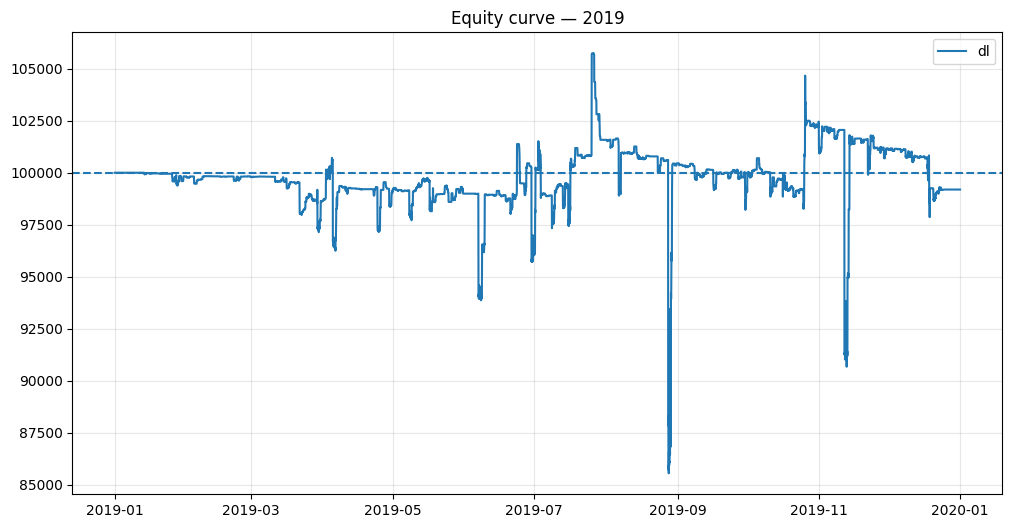

   year     n  mean_target  target_sharpe  profitable
0  2019  2182     0.000043       0.021077    0.111824
1  2020  4058     0.000028       0.012025    0.197141
2  2021  4943     0.000225       0.102244    0.447097
   year  signals  successful_entries  entries_with_target  target_coverage  \
0  2019      641                 242                  125         0.516529   
1  2020     1999                 386                  243         0.629534   
2  2021     3436                 536                  385         0.718284   

   action_match  all_sharpe  executed_sharpe  skipped_sharpe  
0           1.0    0.038887         0.140794        0.005677  
1           1.0    0.017132         0.040616        0.013809  
2           1.0    0.122910         0.147278        0.120080  
 year  score_bin   n  mean_score  mean_target    sharpe  profitable
 2019          0 129    0.000025    -0.000363 -0.127317    0.356589
 2019          1 128    0.000084    -0.000046 -0.011486    0.304688
 2019          

In [ ]:
# =============================================================================================================
# ======================================= YEARLY_DL_ESTIMATION ===============================================
# =============================================================================================================

sys.modules.pop("srcB.dl_model_mfiv", None)
from srcB.dl_model_mfiv import *

dl_bundle_by_year = {}
dl_targets_by_year = {}
dl_output_by_year = {}

for y in YEARS:
    X_df = pd.concat([
        Xq_by_year[y][q]
        for q in QUARTERS
    ]).sort_index().copy()

    garch_df = pd.concat([
        outputs_by_year[y][q]["garch"]
        for q in QUARTERS
    ]).sort_index()

    X_df["garch"] = garch_df.reindex(X_df.index)

    dl_output, dl_bundle, dl_targets = dl_mfiv(
        X_df=X_df,
        option_df=df_raw_by_year[y],
        time_df=d_btc_raw_by_year[y],
        sequence_length=168,
        forward_hours=FORWARD_HOURS,
        delta_target=0.20,
        moving_avg=best_dl_params["moving_avg"],
        individual=best_dl_params["individual"],
        epochs=best_dl_params["epochs_by_year"][y],
        batch_size=best_dl_params["batch_size"],
        learning_rate=best_dl_params["learning_rate"],
        weight_decay=best_dl_params["weight_decay"],
        seed=SEED
    )

    dl_output_by_year[y] = dl_output
    dl_bundle_by_year[y] = dl_bundle
    dl_targets_by_year[y] = dl_targets

    for q in QUARTERS:
        q_index = Xq_by_year[y][q].index
        dl_q = dl_output.reindex(q_index)
        outputs_by_year[y][q] = pd.concat([outputs_by_year[y][q],dl_q], axis=1)


# =============================================================================================================
# ======================================= SAVE DL BUNDLES ====================================================
# =============================================================================================================

os.makedirs(
    "/Users/shah/CODE_BOOK_4/code_document/REPOSITORIES/data/IS/DL",
    exist_ok=True
)

with open(
    "/Users/shah/CODE_BOOK_4/code_document/REPOSITORIES/data/IS/DL/dl_bundle_by_year.pkl",
    "wb"
) as f:
    pickle.dump(dl_bundle_by_year, f)

print("DL bundles saved:", list(dl_bundle_by_year.keys()))


# =============================================================================================================
# ======================================= SAVE OUTPUTS ========================================================
# =============================================================================================================
# Save before the runtime trader adapter so the real TCN columns remain untouched in the cumulative file.

with open(
    "/Users/shah/CODE_BOOK_4/code_document/REPOSITORIES/data/IS/outputs_by_year/outputs_by_year_08.pkl",
    "wb"
) as f:
    pickle.dump(outputs_by_year, f)


# =============================================================================================================
# ======================================= CHECKPOINT 2 - TRADER ONLY =========================================
# =============================================================================================================

# with open(
#     "/Users/shah/CODE_BOOK_4/code_document/REPOSITORIES/data/IS/outputs_by_year/outputs_by_year_08.pkl",
#     "rb"
# ) as f:
#     outputs_by_year = pickle.load(f)


# =============================================================================================================
# ======================================= PREPARE TRADER INPUT ================================================
# =============================================================================================================

for y in YEARS:
    for q in QUARTERS:
        outputs_by_year[y][q]["rv"] = Xq_by_year[y][q]["rv"].reindex(
            outputs_by_year[y][q].index
        )

        outputs_by_year[y][q]["MFIV_24"] = Xq_by_year[y][q]["MFIV_24"].reindex(
            outputs_by_year[y][q].index
        )


# =============================================================================================================
# ======================================= DL TRADER ADAPTER ==================================================
# =============================================================================================================
# DL signals are not altered. The existing trader reads the TCN interface names,
# so only the action and score columns are copied for this runtime trader pass.

for y in YEARS:
    for q in QUARTERS:
        outputs_by_year[y][q]["tcn_action"] = outputs_by_year[y][q]["dl_action"]
        outputs_by_year[y][q]["tcn_best_score"] = outputs_by_year[y][q]["dl_best_score"]


# =============================================================================================================
# ======================================= CACHE FOR WARMUP ====================================================
# =============================================================================================================

CACHE_YEARS = [2019, 2020, 2021]
RUN_BY = "year"

if RUN_BY == "year":
    trader_cache = {
        y: pd.concat(
            [
                outputs_by_year[yy][q]
                for yy in CACHE_YEARS
                if yy <= y
                for q in QUARTERS
            ]
        ).sort_index()
        for y in CACHE_YEARS
    }

elif RUN_BY == "quarter":
    trader_cache = {
        (y, q): pd.concat(
            [
                outputs_by_year[yy][qq]
                for yy in CACHE_YEARS
                for qq in QUARTERS
                if (
                    yy < y
                    or (yy == y and QUARTERS.index(qq) <= QUARTERS.index(q))
                )
            ]
        ).sort_index()
        for y in CACHE_YEARS
        for q in QUARTERS
    }

if RUN_BY == "year":
    PERIODS = YEARS
else:
    PERIODS = [(y, q) for y in YEARS for q in QUARTERS]


# =============================================================================================================
# ======================================= TESTING_MAIN_WITH_CACHE =============================================
# =============================================================================================================

sys.modules.pop("srcB.trader_testing_tcn_v1", None)
from srcB.trader_testing_tcn_v1 import testing_execute_trading_strategy

MODEL = "dl"
RUN_BY = "year"
strategy_results = {}

for YEAR in YEARS:

    market = Market(
        option_df=df_raw_by_year[YEAR],
        time_df=d_btc_raw_by_year[YEAR],
        starting_cash=100_000,
        im_multiplier=0.15,
        mm_buffer_rate=0.05,
    )

    greek_tests = []
    yearly_snapshots = []

    if RUN_BY == "year":
        periods = [None]
    else:
        periods = ["q1", "q2", "q3", "q4"]

    for q in periods:
        snapshots, greek_tests_q = testing_execute_trading_strategy(
            bt_year=YEAR,
            bt_quarter=q,
            model="tcn_mfiv",
            outputs_by_year=outputs_by_year,
            market=market,
            trader_cache=trader_cache,
            run_by=RUN_BY,
            quantity=10,
            expiry_days=30,
            hold_days=7,
            lookback_hours=168,
            mean_hours=12,
            ql=0.10,
            qh=0.90,
            z=1.645,
            forward_hours=FORWARD_HOURS,
        )

        greek_tests.extend(greek_tests_q)
        yearly_snapshots.extend(snapshots)

    if len(market.transactions) == 0:
        raise RuntimeError(f"DL main IS trader produced zero transactions in {YEAR}, go to section TESTING_MAIN_WITH_CACHE")

    history_key = f"{MODEL}_{str(YEAR)[2:]}"
    equity_curve = market.get_equity_history()

    strategy_results[history_key] = {
        "equity_curve": equity_curve,
        "snapshots": yearly_snapshots,
        "greek_tests": greek_tests,
        "orders": list(market.orders),
        "transactions": list(market.transactions),
        "final_cash": market.cash,
        "required_margin": market.get_total_required_margin(),
        "free_liquidity": market.get_free_liquidity(),
    }

print(YEAR, MODEL)


# =============================================================================================================
# ======================================= BASIC CHECKS ========================================================
# =============================================================================================================

print(len(greek_tests))
print(greek_tests[:1])
print(pd.Series([x["action"] for x in market.transactions]).value_counts())
print("outputs:", "dl_action" in outputs_by_year[2019]["q1"].columns)
print("adapter:", "tcn_action" in outputs_by_year[2019]["q1"].columns)
print("cache:", "tcn_action" in trader_cache[2019].columns)
[c for c in trader_cache[2019].columns if c.startswith("dl")]


# =============================================================================================================
# ======================================= SAVE STRATEGY RESULTS ===============================================
# =============================================================================================================

os.makedirs(
    "/Users/shah/CODE_BOOK_4/code_document/REPOSITORIES/data/data_strategy_results",
    exist_ok=True
)

with open(
    "/Users/shah/CODE_BOOK_4/code_document/REPOSITORIES/data/data_strategy_results/strategy_results_dl.pkl",
    "wb"
) as f:
    pickle.dump(strategy_results, f)


# =============================================================================================================
# ======================================= SHARPE ===============================================================
# =============================================================================================================

rows = []

for y in YEARS:
    history_key = f"dl_{str(y)[2:]}"
    snapshots = strategy_results[history_key]["snapshots"]

    equity = pd.Series(
        [s["equity"] for s in snapshots],
        index=[s["time"] for s in snapshots]
    )

    returns = equity.pct_change().dropna()
    sharpe = returns.mean() / returns.std() * np.sqrt(24 * 365)

    rows.append({
        "year": y,
        "model": "dl",
        "sharpe": sharpe
    })

sharpe_table = pd.DataFrame(rows)
print(sharpe_table)


# =============================================================================================================
# ======================================= PLOT EQUITY ==========================================================
# =============================================================================================================

import matplotlib.pyplot as plt

PLOT_YEAR = 2019
plot_key = f"dl_{str(PLOT_YEAR)[2:]}"
result = strategy_results[plot_key]
eq = pd.DataFrame(result["snapshots"]).drop_duplicates("time").sort_values("time")

plt.figure(figsize=(12, 6))
plt.plot(eq["time"], eq["equity"], label="dl")
plt.axhline(100_000, linestyle="--")
plt.title(f"Equity curve — {PLOT_YEAR}")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

# =============================================================================================================
# ======================================= PHASE 2: DIAGNOSTICS FOR DL =======================================
# =============================================================================================================


# =============================================================================================================
# ================================ DL FITTED TARGET-SPACE PERFORMANCE ========================================
# =============================================================================================================
# Target-space Sharpe here is mean/std and is not annualized.

target_cols = [
    "target_long_straddle",
    "target_short_straddle",
    "target_long_strangle",
    "target_short_strangle"
]

rows = []

for y in YEARS:
    test = pd.concat([
        dl_output_by_year[y][["dl_action"]],
        dl_targets_by_year[y][target_cols]
    ], axis=1, sort=False).dropna()

    realized = pd.Series(0.0, index=test.index)

    for action in ["long_straddle", "short_straddle", "long_strangle", "short_strangle"]:
        mask = test["dl_action"] == action
        realized.loc[mask] = test.loc[mask, f"target_{action}"]

    sharpe = realized.mean() / realized.std()

    rows.append({
        "year": y,
        "n": len(realized),
        "mean_target": realized.mean(),
        "target_sharpe": sharpe,
        "profitable": (realized > 0).mean()
    })

target_sharpe = pd.DataFrame(rows)
print(target_sharpe)


# =============================================================================================================
# ================================ DL TARGET PERFORMANCE: EXECUTED VS SKIPPED ================================
# =============================================================================================================
# Question: does the sequential trader execute a representative subset of the DL's fitted opportunities?

target_cols = [
    "target_long_straddle",
    "target_short_straddle",
    "target_long_strangle",
    "target_short_strangle"
]

rows = []

for y in YEARS:

    test = pd.concat([
        dl_output_by_year[y][["dl_action"]],
        dl_targets_by_year[y][target_cols]
    ], axis=1, sort=False).dropna()

    test = test[test["dl_action"] != "no_trade"].copy()
    test["target_pnl"] = 0.0

    for action in ["long_straddle", "short_straddle", "long_strangle", "short_strangle"]:
        m = test["dl_action"] == action
        test.loc[m, "target_pnl"] = test.loc[m, f"target_{action}"]

    entries = pd.DataFrame(
        strategy_results[f"dl_{str(y)[2:]}"]["greek_tests"]
    )

    entries["time"] = pd.to_datetime(entries["time"], utc=True).dt.floor("h")
    entries = entries.drop_duplicates("time")

    covered = entries[entries["time"].isin(test.index)].copy()

    predicted = test["dl_action"].reindex(covered["time"]).to_numpy()
    action_match = (predicted == covered["tcn_action"].to_numpy()).mean()

    executed = test[test.index.isin(covered["time"])]
    skipped = test[~test.index.isin(covered["time"])]

    rows.append({
        "year": y,
        "signals": len(test),
        "successful_entries": len(entries),
        "entries_with_target": len(covered),
        "target_coverage": len(covered) / len(entries) if len(entries) else np.nan,
        "action_match": action_match,
        "all_sharpe": test["target_pnl"].mean() / test["target_pnl"].std(),
        "executed_sharpe": executed["target_pnl"].mean() / executed["target_pnl"].std(),
        "skipped_sharpe": skipped["target_pnl"].mean() / skipped["target_pnl"].std()
    })

execution_check = pd.DataFrame(rows)
print(execution_check)


# =============================================================================================================
# ======================================= DL SCORE CALIBRATION DIAGNOSTIC ===================================
# =============================================================================================================
# Question: are higher DL score bins associated with better realized target outcomes?

rows = []

for y in YEARS:
    test = pd.concat([
        dl_output_by_year[y][["dl_action", "dl_best_score"]],
        dl_targets_by_year[y][target_cols]
    ], axis=1, sort=False).dropna()

    test = test[test["dl_action"] != "no_trade"].copy()
    test["target_pnl"] = 0.0

    for action in ["long_straddle", "short_straddle", "long_strangle", "short_strangle"]:
        m = test["dl_action"] == action
        test.loc[m, "target_pnl"] = test.loc[m, f"target_{action}"]

    test["score_bin"] = pd.qcut(
        test["dl_best_score"],
        5,
        labels=False,
        duplicates="drop"
    )

    x = (
        test.groupby("score_bin")
        .agg(
            n=("target_pnl", "size"),
            mean_score=("dl_best_score", "mean"),
            mean_target=("target_pnl", "mean"),
            sharpe=("target_pnl", lambda z: z.mean() / z.std()),
            profitable=("target_pnl", lambda z: (z > 0).mean())
        )
        .reset_index()
    )

    x["year"] = y
    rows.append(x)

score_check = pd.concat(rows, ignore_index=True)

print(score_check[[
    "year", "score_bin", "n", "mean_score",
    "mean_target", "sharpe", "profitable"
]].to_string(index=False))


# =============================================================================================================
# ======================================= DL SCORE THRESHOLD CALIBRATION ====================================
# =============================================================================================================
# Question: if only signals with dl_best_score >= threshold are retained, does fitted target performance improve?

tests = {}

for y in YEARS:

    x = pd.concat([
        dl_output_by_year[y][["dl_action", "dl_best_score"]],
        dl_targets_by_year[y][target_cols]
    ], axis=1, sort=False).dropna()

    x = x[x["dl_action"] != "no_trade"].copy()
    x["target_pnl"] = 0.0

    for action in ["long_straddle", "short_straddle", "long_strangle", "short_strangle"]:
        m = x["dl_action"] == action
        x.loc[m, "target_pnl"] = x.loc[m, f"target_{action}"]

    tests[y] = x

scores_all = pd.concat([
    tests[y]["dl_best_score"]
    for y in YEARS
])

rows = []

for q in [0, .20, .40, .50, .60, .70, .80, .85, .90]:

    threshold = scores_all.quantile(q)

    for y in YEARS:

        x = tests[y][tests[y]["dl_best_score"] >= threshold]
        sharpe = x["target_pnl"].mean() / x["target_pnl"].std()

        rows.append({
            "quantile": q,
            "threshold": threshold,
            "year": y,
            "n": len(x),
            "mean_target": x["target_pnl"].mean(),
            "sharpe": sharpe
        })

threshold_check = pd.DataFrame(rows)
print(threshold_check.to_string(index=False))

In [ ]:
# =============================================================================================================
# ================================ DL SCORE THRESHOLD TRADER CALIBRATION =====================================
# =============================================================================================================
# Question: does score filtering improve the actual sequential trader?
# Same five-candidate search budget as the TCN: baseline + pooled 70/80/85/90 percentiles.

THRESHOLDS = [
    0.0,
    float(scores_all.quantile(.70)),
    float(scores_all.quantile(.80)),
    float(scores_all.quantile(.85)),
    float(scores_all.quantile(.90))
]

rows = []

for threshold in THRESHOLDS:
    for y in YEARS:

        market = Market(
            option_df=df_raw_by_year[y],
            time_df=d_btc_raw_by_year[y],
            starting_cash=100_000,
            im_multiplier=0.15,
            mm_buffer_rate=0.05,
        )

        snapshots, greek_tests = testing_execute_trading_strategy(
            bt_year=y,
            bt_quarter=None,
            model="tcn_mfiv",
            outputs_by_year=outputs_by_year,
            market=market,
            trader_cache=trader_cache,
            run_by="year",
            tcn_score_threshold=threshold,
            forward_hours = FORWARD_HOURS
        )

        equity = pd.Series(
            [s["equity"] for s in snapshots],
            index=[s["time"] for s in snapshots]
        )

        returns = equity.pct_change().dropna()
        sharpe = returns.mean() / returns.std() * np.sqrt(24 * 365)

        rows.append({
            "threshold": threshold,
            "year": y,
            "trades": len(greek_tests),
            "sharpe": sharpe
        })

threshold_trader_check = pd.DataFrame(rows)
print(threshold_trader_check.to_string(index=False))

 threshold  year  trades    sharpe
  0.000000  2019     242  0.102877
  0.000000  2020     386 -0.347482
  0.000000  2021     536  0.744934
  0.000337  2019      87  0.438139
  0.000337  2020     189 -0.280467
  0.000337  2021     244  0.405934
  0.000461  2019      61 -0.228375
  0.000461  2020     123  0.270874
  0.000461  2021     166  0.579329
  0.000555  2019      48 -0.116806
  0.000555  2020      82  0.446721
  0.000555  2021     125  0.553907
  0.000694  2019      34  0.495207
  0.000694  2020      54  0.298697
  0.000694  2021      84  0.561328
